# KẾ HOẠCH TENSORFLOW: RESNET-18 + LSTM

Baseline TensorFlow/Keras độc lập cho Kaggle T4/P100. ResNet-18 pretrained dùng preset chính thức `resnet_18_imagenet` của KerasHub; bản PyTorch được giữ nguyên.

### Đánh giá run hiện tại

- Kết quả tốt nhất ở epoch 30: validation accuracy **81.96%**, validation Macro-F1 **72.33%**.
- Mô hình học đúng hướng và validation vẫn tăng ở cuối quá trình; chưa có dấu hiệu mất khả năng học.
- Train Macro-F1 khoảng **97.5%**, cao hơn validation hơn 25 điểm: mô hình có overfit nhưng vẫn tổng quát hóa tốt hơn thử nghiệm warm-up/ Balanced Softmax sau đó.
- Thử nghiệm warm-up + Balanced Softmax chỉ đạt Validation Macro-F1 65.71% và Test Macro-F1 61.43%. Vì vậy bản này quay lại recipe đã được kiểm chứng, sau đó chỉ thêm một giai đoạn polish ngắn với learning rate thấp.

> Nếu Kaggle image chưa có KerasHub, chạy một cell riêng: `!pip install -q -U keras-hub`, sau đó restart session. Preset cần Internet hoặc một thư mục preset đã gắn vào Kaggle Input.

## Cell 1 — môi trường và cấu hình


In [1]:
# Cài KerasHub chỉ khi Kaggle chưa có sẵn.
import importlib.util
if importlib.util.find_spec('keras_hub') is None:
    %pip install -q keras-hub
else:
    print('keras_hub đã được cài sẵn.')


keras_hub đã được cài sẵn.


In [2]:
import os, json, random, hashlib
import numpy as np
import pandas as pd
import cv2
import matplotlib.pyplot as plt
from IPython.display import display
from collections import defaultdict
from sklearn.metrics import accuracy_score, f1_score
from tqdm.auto import tqdm

os.environ['TF_CPP_MIN_LOG_LEVEL'] = '2'
import tensorflow as tf
import keras
from keras import layers
try:
    import keras_hub
except ImportError as exc:
    raise ImportError('Hãy chạy !pip install -q -U keras-hub rồi restart session.') from exc

class Config:
    SEED = 42
    DATA_DIR = '/kaggle/input/datasets/lduythi/data-vsl/data'  # Ví dụ: '/kaggle/input/ten-dataset/data'
    INPUT_ROOT = '/kaggle/input'
    OUTPUT_DIR = '/kaggle/working/resnet18_lstm_tf'

    NUM_CLASSES = 100
    NUM_FRAMES = 16
    HEIGHT = 224
    WIDTH = 224
    FILTER_BLANK = True
    PREFLIGHT_DECODE = True
    HORIZONTAL_FLIP = False
    CROP_SCALE = (0.85, 1.0)
    BRIGHTNESS = 0.15
    CONTRAST = 0.15

    RESNET_PRESET = 'resnet_18_imagenet'  # Hoặc đường dẫn preset trong /kaggle/input.
    LSTM_HIDDEN = 256
    TEMPORAL_DROPOUT = 0.0
    CLASSIFIER_DROPOUT = 0.3

    BATCH_SIZE = 2
    GRADIENT_ACCUMULATION_STEPS = 8
    MAIN_EPOCHS = 30        # Recipe cũ đã đạt Val Macro-F1 72.33%.
    POLISH_EPOCHS = 10      # Học tiếp nhẹ sau checkpoint tốt nhất.
    MAIN_LR = 1e-4
    POLISH_LR = 2e-5
    PATIENCE = 8
    LR_PATIENCE = 3
    MIN_LR = 1e-6
    WEIGHT_DECAY = 1e-4
    LABEL_SMOOTHING = 0.1
    USE_WEIGHTED_SAMPLING = True   # Recipe cũ giúp nhóm Tail tốt hơn.
    SAMPLER_POWER = 0.75
    TTA_VIEWS = 1                  # Chỉ bật 3 sau khi TTA cải thiện trên validation.

    # Mỗi từ lấy tối đa hai video test để minh họa inference.
    INFERENCE_WORDS = [
        'Ăn', 'Đi', 'Đẹp', 'Xin lỗi', 'Đồng ý',
        'Uống', 'Xe máy', 'Ô tô', 'Đâu', 'Ủng hộ'
    ]
    INFERENCE_PER_WORD = 2

os.makedirs(Config.OUTPUT_DIR, exist_ok=True)
random.seed(Config.SEED)
np.random.seed(Config.SEED)
keras.utils.set_random_seed(Config.SEED)
tf.config.experimental.enable_op_determinism()
if not tf.config.list_physical_devices('GPU'):
    raise RuntimeError('Notebook chưa bật GPU.')
keras.mixed_precision.set_global_policy('mixed_float16')
print('TensorFlow:', tf.__version__, '| GPU:', tf.config.list_physical_devices('GPU'))

# Bảng cấu hình ngắn gọn để dễ kiểm tra trước khi train.
config_table = pd.DataFrame([
    ('Số frame/video', Config.NUM_FRAMES, 'Uniform/segment sampling'),
    ('Micro-batch', Config.BATCH_SIZE, 'Giảm xuống 1 nếu OOM'),
    ('Batch hiệu dụng', Config.BATCH_SIZE * Config.GRADIENT_ACCUMULATION_STEPS, 'Sau tích lũy gradient'),
    ('Main epochs', Config.MAIN_EPOCHS, 'Fine-tune toàn mạng như run tốt nhất'),
    ('Polish epochs', Config.POLISH_EPOCHS, 'Học tiếp từ checkpoint tốt nhất'),
    ('Main LR', Config.MAIN_LR, 'Learning rate đã đạt Val F1 72.33%'),
    ('Polish LR', Config.POLISH_LR, 'Tinh chỉnh nhẹ sau epoch 30'),
    ('Weighted sampling', Config.USE_WEIGHTED_SAMPLING, 'Giữ hỗ trợ lớp Tail'),
    ('TTA views', Config.TTA_VIEWS, 'Mặc định một view ổn định'),
], columns=['Tham số', 'Giá trị', 'Ghi chú'])
display(config_table)


TensorFlow: 2.20.0 | GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU'), PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU')]


,Tham số,Giá trị,Ghi chú
0,Số frame/video,16,Uniform/segment sampling
1,Micro-batch,2,Giảm xuống 1 nếu OOM
2,Batch hiệu dụng,16,Sau tích lũy gradient
3,Main epochs,30,Fine-tune toàn mạng như run tốt nhất
4,Polish epochs,10,Học tiếp từ checkpoint tốt nhất
5,Main LR,0.0001,Learning rate đã đạt Val F1 72.33%
6,Polish LR,0.00002,Tinh chỉnh nhẹ sau epoch 30
7,Weighted sampling,True,Giữ hỗ trợ lớp Tail
8,TTA views,1,Mặc định một view ổn định


## Cell 2 — metadata và kiểm tra dữ liệu


In [3]:
def resolve_data_dir():
    if Config.DATA_DIR:
        candidates = [Config.DATA_DIR]
    else:
        candidates = []
        for root, dirs, _ in os.walk(Config.INPUT_ROOT):
            if {'train', 'valid', 'test'}.issubset(set(dirs)):
                candidates.append(root)
    candidates = sorted(set(os.path.abspath(x) for x in candidates if os.path.isdir(x)))
    if len(candidates) != 1:
        raise RuntimeError(f'Cần đúng một DATA_DIR; tìm thấy: {candidates}')
    return candidates[0]

def audit_dataset(root):
    records, hash_map, unreadable = [], defaultdict(list), []
    for split in ['train', 'valid', 'test']:
        split_dir = os.path.join(root, split)
        for class_name in sorted(os.listdir(split_dir)):
            class_dir = os.path.join(split_dir, class_name)
            if not os.path.isdir(class_dir):
                continue
            for filename in os.listdir(class_dir):
                if not filename.lower().endswith(('.mp4', '.avi', '.mov', '.mkv')):
                    continue
                path = os.path.join(class_dir, filename)
                md5 = hashlib.md5()
                with open(path, 'rb') as fp:
                    for chunk in iter(lambda: fp.read(65536), b''):
                        md5.update(chunk)
                digest = md5.hexdigest()
                if Config.PREFLIGHT_DECODE:
                    cap = cv2.VideoCapture(path)
                    ok, _ = cap.read() if cap.isOpened() else (False, None)
                    cap.release()
                    if not ok:
                        unreadable.append(path)
                row = {'split': split, 'class': class_name, 'path': path, 'hash': digest}
                records.append(row)
                hash_map[digest].append(row)
    if unreadable:
        raise ValueError(f'{len(unreadable)} video không đọc được: {unreadable[:5]}')
    cross = [h for h, rows in hash_map.items() if len({r['split'] for r in rows}) > 1]
    conflict = [h for h, rows in hash_map.items() if len({r['class'] for r in rows}) > 1]
    if cross or conflict:
        raise ValueError(f'cross_split={len(cross)}, label_conflict={len(conflict)}')
    return pd.DataFrame(records)

DATA_DIR = resolve_data_dir()
all_df = audit_dataset(DATA_DIR)
clean = {
    split: all_df[all_df.split == split].drop_duplicates('hash').copy()
    for split in ['train', 'valid', 'test']
}
classes = sorted(clean['train']['class'].unique())
if len(classes) != Config.NUM_CLASSES:
    raise ValueError(f'Mong đợi 100 lớp, nhận được {len(classes)}')
for split in ['valid', 'test']:
    if set(clean[split]['class'].unique()) != set(classes):
        raise ValueError(f'Nhãn {split} không khớp train.')
class_to_idx = {name: idx for idx, name in enumerate(classes)}
for split, df in clean.items():
    df['label_idx'] = df['class'].map(class_to_idx).astype(int)
    df.to_csv(os.path.join(Config.OUTPUT_DIR, f'{split}_clean.csv'), index=False)
train_df, valid_df, test_df = clean['train'], clean['valid'], clean['test']
with open(os.path.join(Config.OUTPUT_DIR, 'class_to_idx.json'), 'w', encoding='utf-8') as fp:
    json.dump(class_to_idx, fp, ensure_ascii=False, indent=2)
print({name: len(df) for name, df in clean.items()})


{'train': 2175, 'valid': 316, 'test': 281}


## Cell 3 — đọc và biến đổi video


In [4]:
def is_blank(frame):
    return np.std(frame) < 5.0 and (np.mean(frame) < 15.0 or np.mean(frame) > 240.0)

def read_video(path, training):
    cap, frames = cv2.VideoCapture(path), []
    while True:
        ok, frame = cap.read()
        if not ok:
            break
        if Config.FILTER_BLANK and is_blank(frame):
            continue
        frames.append(cv2.cvtColor(frame, cv2.COLOR_BGR2RGB))
    cap.release()
    if not frames and Config.FILTER_BLANK:
        cap = cv2.VideoCapture(path)
        while True:
            ok, frame = cap.read()
            if not ok:
                break
            frames.append(cv2.cvtColor(frame, cv2.COLOR_BGR2RGB))
        cap.release()
    if not frames:
        raise ValueError(f'Không decode được video: {path}')
    total = len(frames)
    if training and total >= Config.NUM_FRAMES:
        bounds = np.linspace(0, total, Config.NUM_FRAMES + 1, dtype=int)
        ids = [random.randint(bounds[i], bounds[i + 1] - 1)
               for i in range(Config.NUM_FRAMES)]
    else:
        ids = np.linspace(0, total - 1, Config.NUM_FRAMES, dtype=int)
    return [frames[i] for i in ids]

def transform_frames(frames, training):
    result = []
    if training:
        h0, w0 = frames[0].shape[:2]
        scale = random.uniform(*Config.CROP_SCALE)
        ch, cw = max(1, int(h0 * scale)), max(1, int(w0 * scale))
        top = random.randint(0, max(0, h0 - ch))
        left = random.randint(0, max(0, w0 - cw))
        brightness = random.uniform(1 - Config.BRIGHTNESS, 1 + Config.BRIGHTNESS)
        contrast = random.uniform(1 - Config.CONTRAST, 1 + Config.CONTRAST)
        flip = Config.HORIZONTAL_FLIP and random.random() < 0.5
        for frame in frames:
            frame = cv2.resize(frame[top:top + ch, left:left + cw], (Config.WIDTH, Config.HEIGHT))
            if flip:
                frame = frame[:, ::-1]
            frame = np.clip((frame.astype(np.float32) - 127.5) * contrast + 127.5, 0, 255)
            result.append(np.clip(frame * brightness, 0, 255))
    else:
        for frame in frames:
            h, w = frame.shape[:2]
            scale = max(Config.HEIGHT / h, Config.WIDTH / w)
            resized = cv2.resize(frame, (round(w * scale), round(h * scale)))
            y, x = (resized.shape[0] - Config.HEIGHT) // 2, (resized.shape[1] - Config.WIDTH) // 2
            result.append(resized[y:y + Config.HEIGHT, x:x + Config.WIDTH].astype(np.float32))
    return np.stack(result).astype(np.float32)

class VideoSequence(keras.utils.Sequence):
    def __init__(self, df, batch_size, training=False):
        super().__init__()
        self.df = df.reset_index(drop=True)
        self.batch_size, self.training = batch_size, training
        self.rng = np.random.default_rng(Config.SEED)
        counts = self.df.label_idx.value_counts().to_dict()
        weights = np.array([1.0 / counts[y] ** Config.SAMPLER_POWER for y in self.df.label_idx])
        self.probabilities = weights / weights.sum()
        self.on_epoch_end()

    def on_epoch_end(self):
        if self.training:
            micro_batches = len(self.df) // self.batch_size
            micro_batches -= micro_batches % Config.GRADIENT_ACCUMULATION_STEPS
            n = micro_batches * self.batch_size
            if Config.USE_WEIGHTED_SAMPLING:
                self.indices = self.rng.choice(
                    len(self.df), n, replace=True, p=self.probabilities
                )
            else:
                # Xáo trộn tự nhiên: không lặp đi lặp lại vài video lớp hiếm.
                self.indices = self.rng.permutation(len(self.df))[:n]
        else:
            self.indices = np.arange(len(self.df))

    def __len__(self):
        return int(np.ceil(len(self.indices) / self.batch_size))

    def __getitem__(self, batch_index):
        ids = self.indices[batch_index*self.batch_size:(batch_index+1)*self.batch_size]
        videos, labels = [], []
        for idx in ids:
            row = self.df.iloc[idx]
            videos.append(transform_frames(read_video(row.path, self.training), self.training))
            labels.append(row.label_idx)
        return np.stack(videos), keras.utils.to_categorical(labels, Config.NUM_CLASSES)

train_seq = VideoSequence(train_df, Config.BATCH_SIZE, True)
valid_seq = VideoSequence(valid_df, Config.BATCH_SIZE, False)
test_seq = VideoSequence(test_df, Config.BATCH_SIZE, False)


## Cell 4 — ResNet-18 + LSTM


In [5]:
class ResNet18LSTM(keras.Model):
    def __init__(self):
        super().__init__()
        self.converter = keras_hub.layers.ResNetImageConverter.from_preset(
            Config.RESNET_PRESET
        )
        self.backbone = keras_hub.models.ResNetBackbone.from_preset(
            Config.RESNET_PRESET,
            load_weights=True
        )
        self.pool = layers.GlobalAveragePooling2D()
        self.temporal_dropout = layers.Dropout(Config.TEMPORAL_DROPOUT)
        self.lstm = layers.LSTM(Config.LSTM_HIDDEN)
        self.norm = layers.LayerNormalization()
        self.dropout = layers.Dropout(Config.CLASSIFIER_DROPOUT)
        self.head = layers.Dense(Config.NUM_CLASSES, dtype='float32')

    def call(self, video, training=False):
        shape = tf.shape(video)
        flat = tf.reshape(video, (-1, Config.HEIGHT, Config.WIDTH, 3))
        flat = self.converter(flat)
        # Cho backbone học đầy đủ như recipe cũ đã đạt kết quả tốt nhất.
        feature_map = self.backbone(flat, training=training)
        features = self.pool(feature_map)
        sequence = tf.reshape(features, (shape[0], Config.NUM_FRAMES, -1))
        sequence = self.temporal_dropout(sequence, training=training)
        x = self.lstm(sequence, training=training)
        x = self.dropout(self.norm(x), training=training)
        return self.head(x)

model = ResNet18LSTM()
smoke = model(tf.zeros((1, Config.NUM_FRAMES, Config.HEIGHT, Config.WIDTH, 3)), training=False)
assert smoke.shape == (1, Config.NUM_CLASSES)
model.summary(expand_nested=True)


I0000 00:00:1792675398.541082      49 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1792675398.548257      49 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


Model: "res_net18lstm"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ res_net_image_converter         │ ?                      │             0 │
│ (ResNetImageConverter)          │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ res_net_backbone                │ (None, None, None,     │    11,186,112 │
│ (ResNetBackbone)                │ 512)                   │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│    └ input_layer (InputLayer)   │ (None, None, None, 3)  │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│    └ conv1_pad (ZeroPadding2D)  │ (None, None, None, 3)  │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│    └ conv1_conv (Conv2D)        │ (None, None, None, 64) │         9,408 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│    └ conv1_bn                   │ (None, None, None, 64) │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│    └ conv1_relu (Activation)    │ (None, None, None, 64) │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│    └ pool1_pad (ZeroPadding2D)  │ (None, None, None, 64) │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│    └ pool1_pool (MaxPooling2D)  │ (None, None, None, 64) │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│    └ stack0_block0_1_conv       │ (None, None, None, 64) │        36,864 │
│ (Conv2D)                        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│    └ stack0_block0_1_bn         │ (None, None, None, 64) │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│    └ stack0_block0_1_relu       │ (None, None, None, 64) │             0 │
│ (Activation)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│    └ stack0_block0_2_conv       │ (None, None, None, 64) │        36,864 │
│ (Conv2D)                        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│    └ stack0_block0_2_bn         │ (None, None, None, 64) │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│    └ stack0_block0_add (Add)    │ (None, None, None, 64) │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│    └ stack0_block0_out          │ (None, None, None, 64) │             0 │
│ (Activation)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│    └ stack0_block1_1_conv       │ (None, None, None, 64) │        36,864 │
│ (Conv2D)                        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│    └ stack0_block1_1_bn         │ (None, None, None, 64) │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│    └ stack0_block1_1_relu       │ (None, None, None, 64) │             0 │
│ (Activation)                    │                        │             

 Total params: 11,999,780 (45.78 MB)

 Trainable params: 11,990,180 (45.74 MB)

 Non-trainable params: 9,600 (37.50 KB)

## Cell 5 — compile và train


In [6]:
standard_loss = keras.losses.CategoricalCrossentropy(
    from_logits=True,
    label_smoothing=Config.LABEL_SMOOTHING
)

def compile_model(learning_rate):
    """Compile toàn bộ ResNet + LSTM bằng một learning rate rõ ràng."""
    try:
        optimizer = keras.optimizers.AdamW(
            learning_rate=learning_rate,
            weight_decay=Config.WEIGHT_DECAY,
            global_clipnorm=1.0,
            gradient_accumulation_steps=Config.GRADIENT_ACCUMULATION_STEPS
        )
    except TypeError as exc:
        raise RuntimeError(
            'TensorFlow/Keras quá cũ; cần optimizer hỗ trợ gradient_accumulation_steps.'
        ) from exc

    model.compile(
        optimizer=optimizer,
        loss=standard_loss,
        metrics=[
            keras.metrics.CategoricalAccuracy(name='accuracy'),
            keras.metrics.F1Score(average='macro', name='macro_f1')
        ]
    )

# Giai đoạn 1: khôi phục đúng recipe cũ đã đạt Test Macro-F1 67.62%.
main_path = os.path.join(Config.OUTPUT_DIR, 'best_main.weights.h5')
model.backbone.trainable = True
compile_model(Config.MAIN_LR)
print('\nGIAI ĐOẠN 1: MAIN TRAINING — fine-tune toàn bộ mô hình')
main_history = model.fit(
    train_seq,
    validation_data=valid_seq,
    epochs=Config.MAIN_EPOCHS,
    callbacks=[
        keras.callbacks.ModelCheckpoint(
            main_path, monitor='val_macro_f1', mode='max',
            save_best_only=True, save_weights_only=True
        ),
        keras.callbacks.CSVLogger(
            os.path.join(Config.OUTPUT_DIR, 'history_main.csv')
        )
    ],
    verbose=1
)
model.load_weights(main_path)

# Giai đoạn 2: học tiếp nhẹ từ checkpoint tốt nhất, không đổi loss/sampler.
polish_path = os.path.join(Config.OUTPUT_DIR, 'best_polish.weights.h5')
compile_model(Config.POLISH_LR)
print('\nGIAI ĐOẠN 2: POLISH — tiếp tục với learning rate nhỏ')
polish_history = model.fit(
    train_seq,
    validation_data=valid_seq,
    initial_epoch=Config.MAIN_EPOCHS,
    epochs=Config.MAIN_EPOCHS + Config.POLISH_EPOCHS,
    callbacks=[
        keras.callbacks.ModelCheckpoint(
            polish_path, monitor='val_macro_f1', mode='max',
            save_best_only=True, save_weights_only=True
        ),
        keras.callbacks.EarlyStopping(
            monitor='val_macro_f1', mode='max', patience=Config.PATIENCE,
            restore_best_weights=False
        ),
        keras.callbacks.ReduceLROnPlateau(
            monitor='val_macro_f1', mode='max', factor=0.5,
            patience=Config.LR_PATIENCE, min_lr=Config.MIN_LR,
            verbose=1
        ),
        keras.callbacks.CSVLogger(
            os.path.join(Config.OUTPUT_DIR, 'history_polish.csv')
        )
    ],
    verbose=1
)

# Giữ checkpoint tốt hơn giữa main training và polish.
main_best = max(main_history.history['val_macro_f1'])
polish_best = max(polish_history.history['val_macro_f1'])
best_checkpoint = polish_path if polish_best >= main_best else main_path
model.load_weights(best_checkpoint)
print(f'Checkpoint tốt nhất: {best_checkpoint}')
print(f'Validation Macro-F1 tốt nhất: {max(main_best, polish_best):.4f}')



GIAI ĐOẠN 1: MAIN TRAINING — fine-tune toàn bộ mô hình
Epoch 1/30
1080/1080 ━━━━━━━━━━━━━━━━━━━━ 272s 234ms/step - accuracy: 0.0181 - loss: 4.9852 - macro_f1: 0.0156 - val_accuracy: 0.0222 - val_loss: 4.5329 - val_macro_f1: 0.0112
Epoch 2/30
1080/1080 ━━━━━━━━━━━━━━━━━━━━ 254s 235ms/step - accuracy: 0.0269 - loss: 4.6535 - macro_f1: 0.0217 - val_accuracy: 0.0411 - val_loss: 4.2096 - val_macro_f1: 0.0171
Epoch 3/30
1080/1080 ━━━━━━━━━━━━━━━━━━━━ 254s 235ms/step - accuracy: 0.0417 - loss: 4.4304 - macro_f1: 0.0373 - val_accuracy: 0.0411 - val_loss: 4.1404 - val_macro_f1: 0.0216
Epoch 4/30
1080/1080 ━━━━━━━━━━━━━━━━━━━━ 257s 238ms/step - accuracy: 0.0616 - loss: 4.1782 - macro_f1: 0.0558 - val_accuracy: 0.0823 - val_loss: 4.0393 - val_macro_f1: 0.0616
Epoch 5/30
1080/1080 ━━━━━━━━━━━━━━━━━━━━ 258s 239ms/step - accuracy: 0.1060 - loss: 3.8837 - macro_f1: 0.1097 - val_accuracy: 0.1361 - val_loss: 3.8758 - val_macro_f1: 0.0814
Epoch 6/30
1080/1080 ━━━━━━━━━━━━━━━━━━━━ 254s 235ms/step - accu

## Cell 6 — vẽ biểu đồ quá trình huấn luyện


,epoch,phase,accuracy,learning_rate,loss,macro_f1,val_accuracy,val_loss,val_macro_f1
35,36,Polish,0.991204,0.00002,0.975907,0.992203,0.838608,1.468091,0.731701
36,37,Polish,0.988426,0.00001,0.976455,0.989120,0.816456,1.489388,0.705698
37,38,Polish,0.992130,0.00001,0.964078,0.992640,0.854430,1.449539,0.771984
38,39,Polish,0.994444,0.00001,0.967784,0.994807,0.851266,1.446800,0.740276
39,40,Polish,0.994907,0.00001,0.965789,0.995004,0.832278,1.482312,0.748207


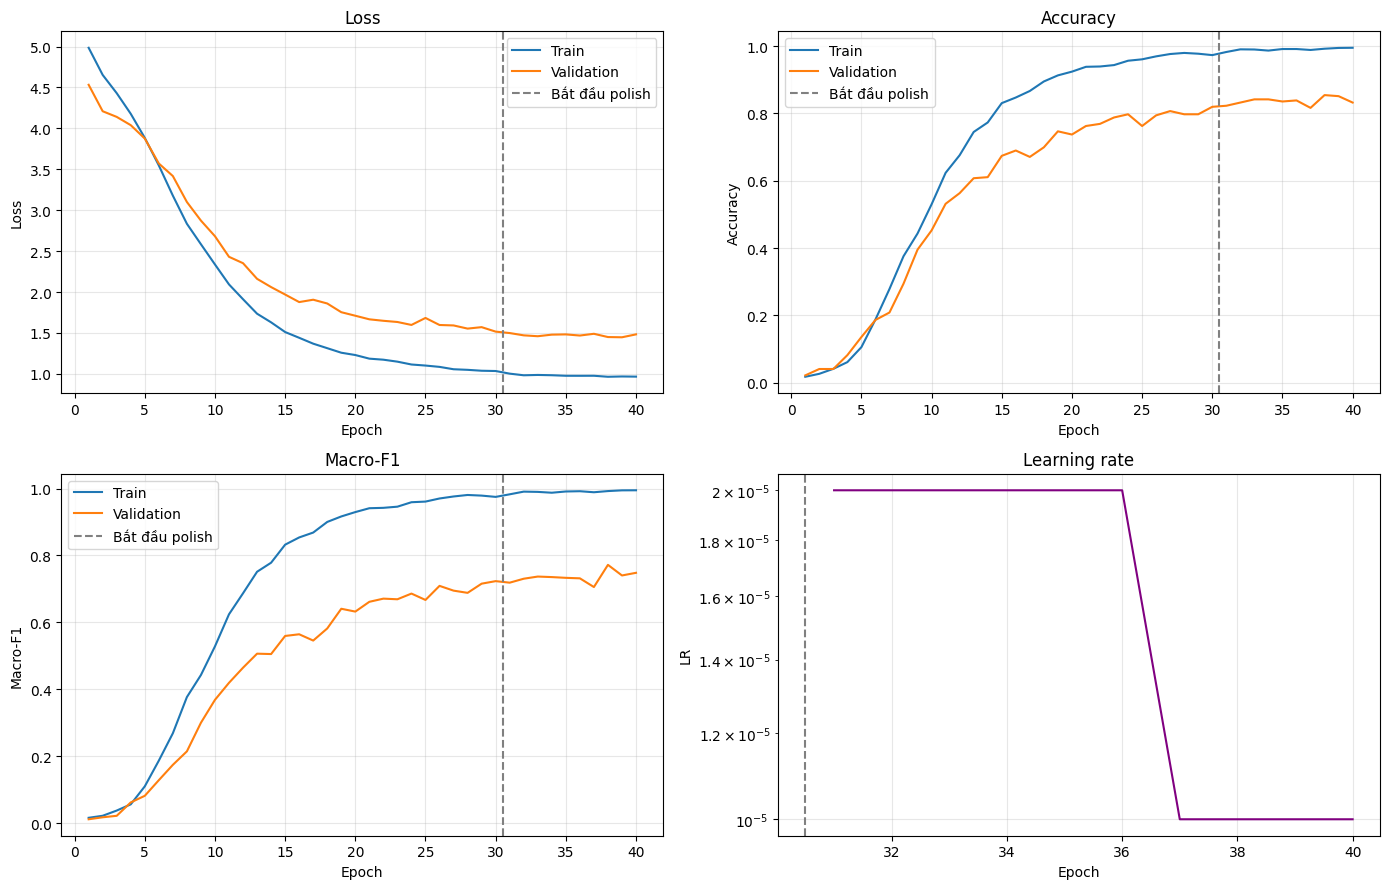

Đã lưu biểu đồ: /kaggle/working/resnet18_lstm_tf/training_curves.png


In [7]:
def combine_histories(first, second):
    """Ghép lịch sử main training và polish thành một DataFrame."""
    keys = sorted(set(first.history) | set(second.history))
    rows = []
    for phase, history_object in [('Main', first), ('Polish', second)]:
        length = len(history_object.epoch)
        for i in range(length):
            row = {'phase': phase}
            for key in keys:
                values = history_object.history.get(key, [np.nan] * length)
                row[key] = values[i]
            rows.append(row)
    result = pd.DataFrame(rows)
    result.insert(0, 'epoch', np.arange(1, len(result) + 1))
    return result

history_df = combine_histories(main_history, polish_history)
history_df.to_csv(os.path.join(Config.OUTPUT_DIR, 'training_history.csv'), index=False)
display(history_df.tail())

fig, axes = plt.subplots(2, 2, figsize=(14, 9))
plots = [
    ('loss', 'val_loss', 'Loss'),
    ('accuracy', 'val_accuracy', 'Accuracy'),
    ('macro_f1', 'val_macro_f1', 'Macro-F1'),
]
for axis, (train_key, val_key, title) in zip(axes.flat[:3], plots):
    axis.plot(history_df.epoch, history_df[train_key], label='Train')
    axis.plot(history_df.epoch, history_df[val_key], label='Validation')
    axis.axvline(Config.MAIN_EPOCHS + 0.5, color='gray', linestyle='--', label='Bắt đầu polish')
    axis.set(title=title, xlabel='Epoch', ylabel=title)
    axis.grid(alpha=0.3)
    axis.legend()

lr_key = 'learning_rate' if 'learning_rate' in history_df else 'lr'
if lr_key not in history_df:
    history_df[lr_key] = np.nan
axes[1, 1].plot(history_df.epoch, history_df[lr_key], color='purple')
axes[1, 1].axvline(Config.MAIN_EPOCHS + 0.5, color='gray', linestyle='--')
axes[1, 1].set(title='Learning rate', xlabel='Epoch', ylabel='LR')
axes[1, 1].set_yscale('log')
axes[1, 1].grid(alpha=0.3)

plt.tight_layout()
plot_path = os.path.join(Config.OUTPUT_DIR, 'training_curves.png')
plt.savefig(plot_path, dpi=160, bbox_inches='tight')
plt.show()
print('Đã lưu biểu đồ:', plot_path)


## Cell 7 — test và cohort report


In [8]:
test_probability = model.predict(test_seq, verbose=1)
test_prediction = test_probability.argmax(axis=1)
test_true = test_df.label_idx.to_numpy()
all_labels = np.arange(Config.NUM_CLASSES)

test_acc = accuracy_score(test_true, test_prediction)
test_macro_f1 = f1_score(test_true, test_prediction, labels=all_labels,
                         average='macro', zero_division=0)
test_weighted_f1 = f1_score(test_true, test_prediction, labels=all_labels,
                            average='weighted', zero_division=0)
print(f'Accuracy={test_acc*100:.2f}% | Macro-F1={test_macro_f1*100:.2f}% | Weighted-F1={test_weighted_f1*100:.2f}%')

per_class_f1 = f1_score(test_true, test_prediction, labels=all_labels,
                        average=None, zero_division=0)
per_class = pd.DataFrame({
    'label_idx': all_labels,
    'class': [classes[i] for i in all_labels],
    'support': np.bincount(test_true, minlength=Config.NUM_CLASSES),
    'f1': per_class_f1
})
per_class.to_csv(os.path.join(Config.OUTPUT_DIR, 'test_per_class_f1.csv'), index=False)

counts = train_df.label_idx.value_counts().to_dict()
cohorts = {
    'Head (>30)': [i for i, n in counts.items() if n > 30],
    'Medium (20-30)': [i for i, n in counts.items() if 20 <= n <= 30],
    'Tail (<20)': [i for i, n in counts.items() if n < 20]
}
cohort_report = pd.DataFrame([
    {'cohort': name, 'num_classes': len(ids),
     'macro_f1': float(np.mean(per_class_f1[ids])) if ids else 0.0}
    for name, ids in cohorts.items()
])
print(cohort_report.to_string(index=False))
cohort_report.to_csv(os.path.join(Config.OUTPUT_DIR, 'test_cohort.csv'), index=False)


141/141 ━━━━━━━━━━━━━━━━━━━━ 22s 148ms/step
Accuracy=82.56% | Macro-F1=70.04% | Weighted-F1=80.31%
        cohort  num_classes  macro_f1
    Head (>30)           32  0.893795
Medium (20-30)           25  0.815088
    Tail (<20)           43  0.489830


## Cell 8 — Temporal Test-Time Augmentation (TTA)


In [9]:
def read_video_views(path, num_views=3):
    """Tạo nhiều cách lấy 16 frame từ cùng một video để dự đoán ổn định hơn."""
    cap, frames = cv2.VideoCapture(path), []
    while True:
        ok, frame = cap.read()
        if not ok:
            break
        if Config.FILTER_BLANK and is_blank(frame):
            continue
        frames.append(cv2.cvtColor(frame, cv2.COLOR_BGR2RGB))
    cap.release()

    if not frames and Config.FILTER_BLANK:
        cap = cv2.VideoCapture(path)
        while True:
            ok, frame = cap.read()
            if not ok:
                break
            frames.append(cv2.cvtColor(frame, cv2.COLOR_BGR2RGB))
        cap.release()

    if not frames:
        raise ValueError(f'Không decode được video: {path}')

    total = len(frames)
    if total < Config.NUM_FRAMES:
        indices = np.linspace(0, total - 1, Config.NUM_FRAMES, dtype=int)
        return [[frames[i] for i in indices]]

    boundaries = np.linspace(0, total, Config.NUM_FRAMES + 1, dtype=int)
    fractions = np.linspace(0.15, 0.85, num_views)
    views = []
    for fraction in fractions:
        indices = []
        for i in range(Config.NUM_FRAMES):
            start, end = boundaries[i], boundaries[i + 1]
            index = start + int((end - start - 1) * fraction)
            indices.append(min(index, end - 1))
        views.append([frames[i] for i in indices])
    return views

def predict_probability_tta(path):
    """Dự đoán một view chuẩn; chỉ trung bình nhiều view khi TTA_VIEWS > 1."""
    if Config.TTA_VIEWS <= 1:
        frames = transform_frames(read_video(path, training=False), training=False)
        logits = model(frames[None, ...], training=False)
        return tf.nn.softmax(logits, axis=1).numpy()[0]

    views = read_video_views(path, Config.TTA_VIEWS)
    batch = np.stack([transform_frames(view, False) for view in views])
    logits = model(batch, training=False)
    return tf.nn.softmax(logits, axis=1).numpy().mean(axis=0)

def evaluate_tta(dataframe, description):
    probabilities = []
    for row in tqdm(dataframe.itertuples(index=False), total=len(dataframe), desc=description):
        probabilities.append(predict_probability_tta(row.path))
    probabilities = np.stack(probabilities)
    predictions = probabilities.argmax(axis=1)
    targets = dataframe.label_idx.to_numpy()
    return targets, predictions, probabilities

# Không chạy lại toàn bộ test khi TTA đang tắt. Chỉ bật TTA sau khi nó tốt hơn trên validation.
if Config.TTA_VIEWS > 1:
    tta_true, tta_prediction, tta_probability = evaluate_tta(test_df, 'Test TTA')
else:
    print('TTA đang tắt (TTA_VIEWS=1); dùng lại kết quả đánh giá chuẩn.')
    tta_true = test_true
    tta_prediction = test_prediction
    tta_probability = test_probability
tta_accuracy = accuracy_score(tta_true, tta_prediction)
tta_macro_f1 = f1_score(
    tta_true, tta_prediction, labels=all_labels,
    average='macro', zero_division=0
)
tta_weighted_f1 = f1_score(
    tta_true, tta_prediction, labels=all_labels,
    average='weighted', zero_division=0
)
print(
    f'TTA Accuracy={tta_accuracy*100:.2f}% | '
    f'Macro-F1={tta_macro_f1*100:.2f}% | '
    f'Weighted-F1={tta_weighted_f1*100:.2f}%'
)

tta_per_class_f1 = f1_score(
    tta_true, tta_prediction, labels=all_labels,
    average=None, zero_division=0
)
tta_cohort_report = pd.DataFrame([
    {
        'cohort': name,
        'num_classes': len(ids),
        'macro_f1': float(np.mean(tta_per_class_f1[ids])) if ids else 0.0
    }
    for name, ids in cohorts.items()
])
display(tta_cohort_report)
tta_cohort_report.to_csv(
    os.path.join(Config.OUTPUT_DIR, 'test_cohort_tta.csv'), index=False
)


TTA đang tắt (TTA_VIEWS=1); dùng lại kết quả đánh giá chuẩn.
TTA Accuracy=82.56% | Macro-F1=70.04% | Weighted-F1=80.31%


,cohort,num_classes,macro_f1
0,Head (>30),32,0.893795
1,Medium (20-30),25,0.815088
2,Tail (<20),43,0.489830


## Cell 9 — lưu cấu hình và inference nhiều từ


In [10]:
model_config = {
    'architecture': 'ResNet-18 + LSTM (TensorFlow/KerasHub)',
    'preset': Config.RESNET_PRESET,
    'num_classes': Config.NUM_CLASSES,
    'num_frames': Config.NUM_FRAMES,
    'height': Config.HEIGHT,
    'width': Config.WIDTH,
    'lstm_hidden': Config.LSTM_HIDDEN,
    'temporal_dropout': Config.TEMPORAL_DROPOUT,
    'classifier_dropout': Config.CLASSIFIER_DROPOUT,
    'main_epochs': Config.MAIN_EPOCHS,
    'polish_epochs': Config.POLISH_EPOCHS,
    'main_lr': Config.MAIN_LR,
    'polish_lr': Config.POLISH_LR,
    'label_smoothing': Config.LABEL_SMOOTHING,
    'use_weighted_sampling': Config.USE_WEIGHTED_SAMPLING,
    'sampler_power': Config.SAMPLER_POWER,
    'tta_views': Config.TTA_VIEWS,
    'checkpoint': os.path.basename(best_checkpoint)
}
with open(os.path.join(Config.OUTPUT_DIR, 'model_config.json'), 'w') as fp:
    json.dump(model_config, fp, indent=2)

def predict_video(path):
    """Trả về Top-3; dùng TTA khi TTA_VIEWS lớn hơn 1."""
    probability = predict_probability_tta(path)
    top = np.argsort(probability)[-3:][::-1]
    return [(classes[i], float(probability[i])) for i in top]

def test_multiple_words(words, samples_per_word=2):
    """Lấy nhiều từ từ test set và in Top-3 để kiểm tra định tính."""
    rows = []
    for word in words:
        candidates = test_df[test_df['class'] == word]
        if candidates.empty:
            print(f'Bỏ qua "{word}": không có trong test set.')
            continue
        selected = candidates.sample(
            n=min(samples_per_word, len(candidates)),
            random_state=Config.SEED
        )
        for _, sample in selected.iterrows():
            top3 = predict_video(sample['path'])
            rows.append({
                'Từ thật': word,
                'Video': os.path.basename(sample['path']),
                'Top-1': top3[0][0],
                'Độ tin cậy Top-1': top3[0][1],
                'Đúng Top-1': top3[0][0] == word,
                'Top-3': ' | '.join(f'{name}: {prob*100:.1f}%' for name, prob in top3)
            })
    return pd.DataFrame(rows)

inference_results = test_multiple_words(
    Config.INFERENCE_WORDS,
    Config.INFERENCE_PER_WORD
)
display(inference_results)
if len(inference_results):
    demo_accuracy = inference_results['Đúng Top-1'].mean()
    print(f'Độ chính xác trên nhóm minh họa: {demo_accuracy*100:.2f}% '
          f'({inference_results["Đúng Top-1"].sum()}/{len(inference_results)})')
    inference_results.to_csv(
        os.path.join(Config.OUTPUT_DIR, 'multi_word_inference.csv'),
        index=False
    )


,Từ thật,Video,Top-1,Độ tin cậy Top-1,Đúng Top-1,Top-3
0,Ăn,205907.mp4,Ăn,0.628780,True,Ăn: 62.9% | Tôi: 7.0% | Nghe: 5.6%
1,Ăn,330283.mp4,Mua,0.212901,False,Mua: 21.3% | Bàn tay: 17.3% | Đâu: 6.3%
2,Đi,185168.mp4,Đi,0.829063,True,Đi: 82.9% | Áp dụng: 4.2% | Chúng ta: 1.2%
3,Đi,462831.mp4,Đi,0.401300,True,Đi: 40.1% | Học sinh: 5.2% | Chào: 4.5%
4,Đẹp,643269.mp4,Đẹp,0.168305,True,Đẹp: 16.8% | Trưa: 14.8% | Nghe: 11.4%
5,Đẹp,553633.mp4,Đẹp,0.462085,True,Đẹp: 46.2% | Khóc: 6.1% | Nghe: 5.6%
6,Xin lỗi,505426.mp4,Xin lỗi,0.614166,True,Xin lỗi: 61.4% | Xa: 8.5% | Nhà: 3.8%
7,Xin lỗi,455505.mp4,Xin lỗi,0.460990,True,Xin lỗi: 46.1% | Rau: 9.1% | Nhà: 8.0%
8,Đồng ý,770030.mp4,Đồng ý,0.180829,True,Đồng ý: 18.1% | Bệnh viện: 8.9% | Virus: 6.3%
9,Đồng ý,575575.mp4,Đồng ý,0.670138,True,Đồng ý: 67.0% | Trưa: 6.4% | Nhìn: 5.1%


Độ chính xác trên nhóm minh họa: 82.35% (14/17)


## Protocol so sánh

1. Hai bản TensorFlow dùng cùng split, 16 frame, augmentation, weighted sampling, label smoothing và batch hiệu dụng 16.
2. ResNet mặc định micro-batch 2; ConvNeXt mặc định 1. Giảm về 1 nếu ResNet OOM.
3. Để kiểm tra notebook chạy thông trước, tạm đặt `MAIN_EPOCHS=1` và `POLISH_EPOCHS=1`; không dùng kết quả này để so sánh chất lượng.
4. Chọn checkpoint bằng Validation Macro-F1 và chỉ đánh giá test sau khi khóa cấu hình.
5. Nếu có ngân sách, chạy ít nhất ba seed và báo cáo mean ± standard deviation.
